# P2.15 — New dwellings against households, by size

**Question:** RQ2.6 (how has new-build supply compared with demand for different property types?). Companion of `p2_05` (supply
against households in total).

Supply is completed family dwellings by number of bedrooms (INE: T0-T1, T2, T3, T4 or more); demand is private households by
number of persons (census 2011 and 2021). The two are paired one to one (T0-T1 with 1 person, T2 with 2, T3 with 3, T4+ with 4 or
more). That is a nominal pairing, not a rule: a couple can live in a T3 and a family can share a T2. So this compares two mixes, not
a count of homes missing, and only flows: the stock of dwellings by number of rooms is not in the data, so who lives in what is not
observed. Municipal values are 2011-2021 sums of completions against the two censuses.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats

from pthousing.analysis import housing_mix
from pthousing.config import PROCESSED
from pthousing.data import interim, typology
from pthousing.viz import charts, style

style.apply_style()
households = interim.read("ine_households_size")
construction = interim.read("ine_construction")
panel = pd.read_parquet(PROCESSED / "panel_municipality_year.parquet")

## Step 1 — The national mix
Households grew only at the small end. Completions between the censuses were mostly T3 and larger.

,households_2011_n,households_2021_n,households_change_n,completed_n,households_2011_share_pct,households_2021_share_pct,households_change_share_pct,completed_share_pct
size,,,,,,,,
1,866827,1027871,161044,14979.0,21.4,24.8,152.8,9.9
2,1277558,1382996,105438,32914.0,31.6,33.3,100.1,21.8
3,965781,894451,-71330,74620.0,23.9,21.6,-67.7,49.4
4plus,933560,843778,-89782,28441.0,23.1,20.3,-85.2,18.8


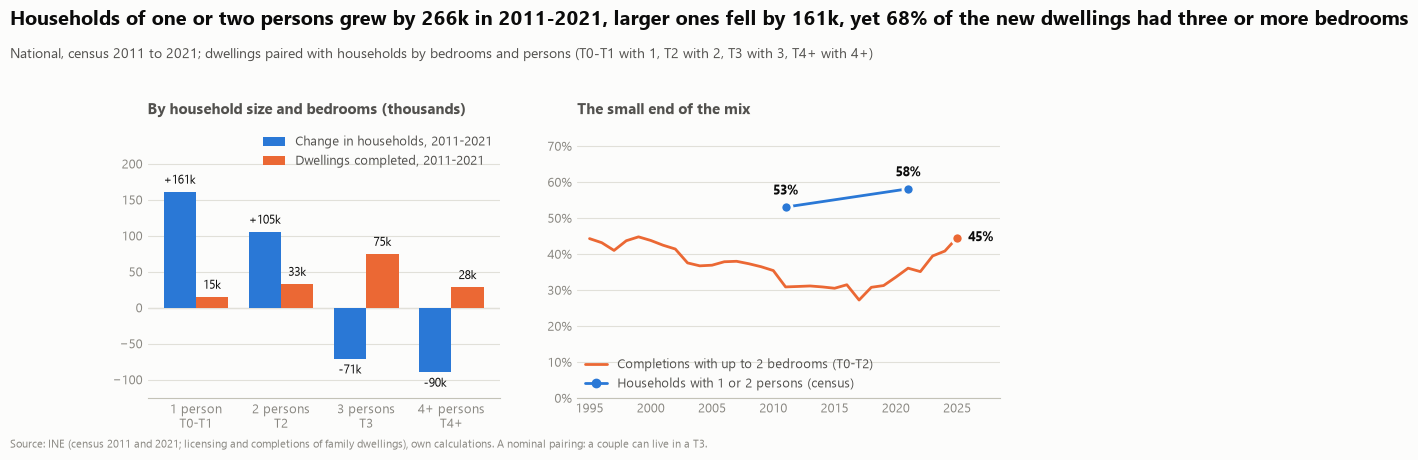

In [2]:
comparison = housing_mix.national_comparison(households, construction)
small_share = housing_mix.small_share_by_year(construction)
small_households = {
    year: 100
    * households[(households["census_year"] == year) & households["size"].isin(housing_mix.SMALL)][
        "households_n"
    ].sum()
    / households.loc[households["census_year"] == year, "households_n"].sum()
    for year in (2011, 2021)
}
fig = charts.new_build_vs_households(comparison, small_share, small_households)
style.save_fig(fig, "p2", "new_build_vs_households")
style.save_table(comparison.round(1).reset_index(), "p2", "households_and_completions_by_size")
comparison.round(1)

## Step 2 — Completions by size over thirty years
The small share of completions fell from 44% in 1995 to a low of 27% in 2017 and has been rising since, to 45% in 2025: the mix is
now moving the way households did.

In [3]:
by_size = construction[construction["size"].isin(housing_mix.SIZE_PAIRS)]
shares = (
    by_size.groupby(["year", "size"])["completed_n"]
    .sum()
    .unstack("size")
    .pipe(lambda t: 100 * t.div(t.sum(axis=1), axis=0))
)
style.save_table(shares.round(1).reset_index(), "p2", "completion_shares_by_bedrooms")
shares.loc[[1995, 2000, 2005, 2010, 2015, 2020, 2025]].round(1)

size,br_0_1,br_2,br_3,br_4plus
year,,,,
1995,10.1,34.2,43.7,12.1
2000,9.3,34.4,43.2,13.0
2005,9.2,27.6,46.6,16.5
2010,10.4,25.0,45.7,18.9
2015,9.4,21.1,49.1,20.4
2020,11.9,21.6,50.8,15.6
2025,17.0,27.6,42.7,12.7


## Step 3 — Where does new building lag households most?
Per municipality, `small_gap_pp` is the share of 2021 households with one or two persons minus the share of 2011-2021 completions
with up to two bedrooms (municipalities with fewer than 50 completions are left out). By density class, and against prices.

In [4]:
gap = housing_mix.small_dwelling_gap(households, construction).merge(
    typology.read()[["muni_code", "density_class", "coast_class", "tourist"]], on="muni_code"
)
latest, before = (
    panel[panel["year"] == 2024].set_index("muni_code"),
    panel[panel["year"] == 2019].set_index("muni_code"),
)
gap["pti_years_2024"] = gap["muni_code"].map(latest["pti_years"])
gap["real_price_change_2019_2024_pct"] = gap["muni_code"].map(
    100 * np.log(latest["price_sqm_eur_real"] / before["price_sqm_eur_real"])
)
order = pd.CategoricalDtype(["urban", "intermediate", "rural"], ordered=True)
by_density = (
    gap.assign(density_class=gap["density_class"].astype(order))
    .groupby("density_class", observed=True)[
        ["small_households_pct", "small_completions_pct", "small_gap_pp", "pti_years_2024"]
    ]
    .median()
)
by_density["municipalities_n"] = gap.groupby("density_class")["small_gap_pp"].count()
style.save_table(by_density.round(1).reset_index(), "p2", "small_dwelling_gap_by_density")
by_density.round(1)

,small_households_pct,small_completions_pct,small_gap_pp,pti_years_2024,municipalities_n
density_class,,,,,
urban,56.6,30.7,23.3,16.1,35
intermediate,56.2,26.7,27.9,13.2,83
rural,62.9,23.7,37.6,6.8,148


In [5]:
rows = {}
for col in ("pti_years_2024", "real_price_change_2019_2024_pct"):
    d = gap[["small_gap_pp", col]].dropna()
    rho, p = stats.spearmanr(d["small_gap_pp"], d[col])
    rows[col] = {"spearman_rho": rho, "p_value": p, "n": len(d)}
assoc = pd.DataFrame(rows).T
gap["gap_tercile"] = pd.qcut(
    gap["small_gap_pp"], 3, labels=["smallest gap", "middle", "largest gap"]
)
terciles = gap.groupby("gap_tercile", observed=True)[
    [
        "small_gap_pp",
        "small_households_pct",
        "small_completions_pct",
        "pti_years_2024",
        "real_price_change_2019_2024_pct",
    ]
].median()
terciles["urban_n"] = (
    gap[gap["density_class"] == "urban"].groupby("gap_tercile", observed=True)["muni_code"].count()
)
style.save_table(
    assoc.round(3).reset_index(names="outcome"), "p2", "small_dwelling_gap_association"
)
style.save_table(terciles.round(1).reset_index(), "p2", "small_dwelling_gap_terciles")
print(assoc.round(3).to_string())
terciles.round(1)

                                 spearman_rho  p_value      n
pti_years_2024                         -0.656      0.0  265.0
real_price_change_2019_2024_pct        -0.394      0.0  257.0


,small_gap_pp,small_households_pct,small_completions_pct,pti_years_2024,real_price_change_2019_2024_pct,urban_n
gap_tercile,,,,,,
smallest gap,17.4,57.0,39.2,14.9,33.5,25
middle,33.4,59.3,25.9,10.9,26.7,7
largest gap,45.0,63.3,17.2,6.7,17.0,3


## Key numbers

In [6]:
c = comparison
print(
    f"households 2011-2021: 1 person {c.loc['1', 'households_change_n']:+,.0f}, 2 persons {c.loc['2', 'households_change_n']:+,.0f}, "
    f"3 persons {c.loc['3', 'households_change_n']:+,.0f}, 4+ {c.loc['4plus', 'households_change_n']:+,.0f}; "
    f"one- and two-person share {small_households[2011]:.1f}% -> {small_households[2021]:.1f}%"
)
print(
    f"completions 2011-2021 (T0-T1, T2, T3, T4+): {', '.join(f'{v:,.0f} ({s:.0f}%)' for v, s in zip(c['completed_n'], c['completed_share_pct'], strict=True))}; "
    f"up to two bedrooms {c.loc[['1', '2'], 'completed_share_pct'].sum():.0f}% against {small_households[2021]:.0f}% of households"
)
print(
    f"small share of completions: 1995 {small_share.loc[1995]:.0f}%, low {small_share.min():.0f}% ({small_share.idxmin()}), 2021 {small_share.loc[2021]:.0f}%, 2025 {small_share.loc[2025]:.0f}%"
)
print(
    f"municipal gap (n {gap['small_gap_pp'].count()}): median {gap['small_gap_pp'].median():.0f} pp, positive in {100 * (gap['small_gap_pp'] > 0).sum() / gap['small_gap_pp'].count():.0f}%"
)
for name, r in by_density.iterrows():
    print(
        f"  {name}: households {r.small_households_pct:.0f}%, completions {r.small_completions_pct:.0f}%, gap {r.small_gap_pp:.0f} pp, price-to-income {r.pti_years_2024:.1f}, n {int(r.municipalities_n)}"
    )
for name, r in assoc.iterrows():
    print(f"  Spearman gap vs {name}: {r.spearman_rho:+.2f} (p {r.p_value:.3f}, n {int(r.n)})")

households 2011-2021: 1 person +161,044, 2 persons +105,438, 3 persons -71,330, 4+ -89,782; one- and two-person share 53.0% -> 58.1%
completions 2011-2021 (T0-T1, T2, T3, T4+): 14,979 (10%), 32,914 (22%), 74,620 (49%), 28,441 (19%); up to two bedrooms 32% against 58% of households
small share of completions: 1995 44%, low 27% (2017), 2021 36%, 2025 45%
municipal gap (n 266): median 33 pp, positive in 97%
  urban: households 57%, completions 31%, gap 23 pp, price-to-income 16.1, n 35
  intermediate: households 56%, completions 27%, gap 28 pp, price-to-income 13.2, n 83
  rural: households 63%, completions 24%, gap 38 pp, price-to-income 6.8, n 148
  Spearman gap vs pti_years_2024: -0.66 (p 0.000, n 265)
  Spearman gap vs real_price_change_2019_2024_pct: -0.39 (p 0.000, n 257)
